# Standard perturbation theory, TSD, and DMRG energies for four charge distances

Energies are calculated with scripts/string_potential_classical.py for four charge configurations separately.

```
python string_potential_classical.py 8x8 20 21
```

In [1]:
import logging
import numpy as np
import h5py
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

logging.basicConfig(level=logging.INFO)

Text(0, 0.5, '$E - E_{DMRG}$')

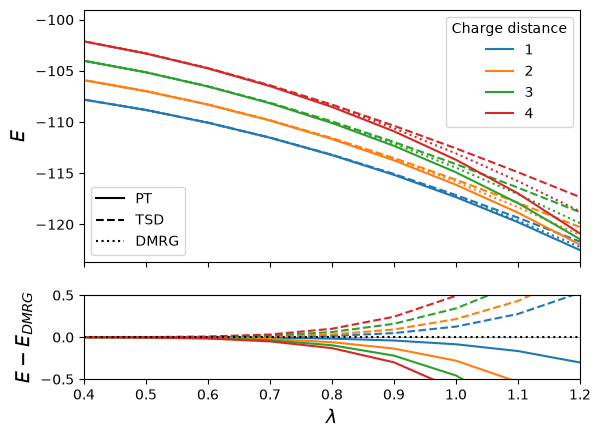

In [12]:
fig, axs = plt.subplots(2, 1, sharex=True, height_ratios=(3, 1))

for ch2 in [21, 22, 23, 24]:
    charges = [20, ch2]
    filename = f'/data/iiyama/2dz2/string_potential/8x8_{charges[0]}-{charges[1]}_pt6.h5'
    with h5py.File(filename, 'r') as source:
        mus = source['mus'][()]
        pt_energies = source['pt_energies'][()]
        dmrg_energies = source['dmrg_energies'][()]
        tsd_energies = source['tsd_energies'][()]

    pt_line, = axs[0].plot(mus, pt_energies, label=f'{charges[1] - charges[0]}')
    axs[0].plot(mus, tsd_energies, color=pt_line.get_color(), linestyle='--')
    axs[0].plot(mus, dmrg_energies, color=pt_line.get_color(), linestyle=':')
    axs[1].plot(mus, pt_energies - dmrg_energies, color=pt_line.get_color())
    axs[1].plot(mus, tsd_energies - dmrg_energies, color=pt_line.get_color(), linestyle='--')

axs[0].set_xlim(0.4, 1.2)
axs[0].set_ylabel('$E$', fontsize=14)
distance_legend = axs[0].legend(title='Charge distance', fontsize=10, loc='upper right')
axs[0].add_artist(distance_legend)
style_handles = [
    Line2D([], [], color='k', linestyle='-', label='PT'),
    Line2D([], [], color='k', linestyle='--', label='TSD'),
    Line2D([], [], color='k', linestyle=':', label='DMRG'),
]
axs[0].legend(handles=style_handles, fontsize=10, loc='lower left')
axs[1].axhline(0., color='k', linestyle=':')
axs[1].grid(axis='y')
axs[1].set_xlim(0.4, 1.2)
axs[1].set_ylim(-0.5, 0.5)
axs[1].set_xlabel(r'$\lambda$', fontsize=14)
axs[1].set_ylabel('$E - E_{DMRG}$', fontsize=14)

## 